# Лабораторная работа: линейная алгебра для Data Science


## Назначение работы

Эта лабораторная работа связывает базовые операции линейной алгебры с тем, как данные представлены и обрабатываются в Data Science. Сначала каждое действие выполняется аналитически, затем записывается математически в Markdown и только после этого проверяется с помощью NumPy. В заключительной части готовый код показывает базовую идею метода главных компонент (PCA) и сингулярного разложения (SVD): от студента требуется не программировать эти алгоритмы с нуля, а понимать входные данные, читать результат и объяснять его пользу.

Работа рассчитана на интенсивное занятие с обязательным домашним продолжением. На занятии следует пройти материал до раздела 8 включительно. Если какая-либо из предшествующих задач не завершена в аудитории, она также входит в домашнюю часть. Разделы 9 и 10 обязательны для самостоятельного завершения.

Основной источник теории — пособие [«Линейная алгебра»](../02-linear-algebra/linear-algebra.pdf). Из [«Высшей математики. Практикума»](../00-input/stuff/02-Высшая-математика-практикум.pdf) взята только часть стартовых аналитических условий. Остальные аналитические вопросы, задачи на общем наборе данных и вычислительные исследования специально составлены для этой работы по материалам пособия. Поэтому отсутствие ссылки на практикум означает не пропуск источника, а авторское задание внутри общей канвы.


## Как работать с материалом

Каждый этап помечен способом работы:

- **[Бумага]** — решить аналитически без NumPy;
- **[Markdown]** — перенести ход решения в Markdown-ячейку ноутбука, используя LaTeX;
- **[Python]** — проверить вычисления или выполнить готовый вычислительный фрагмент;
- **[Интерпретация]** — объяснить результат обычными словами применительно к данным.

Ответ считается полным, если виден не только итог, но и ход рассуждения: исходные объекты, используемое правило, промежуточные вычисления, проверка и смысл результата. Десятичное число не заменяет точное значение, если ответ естественно выражается дробью, корнем или углом.


### Единая канва

Мы будем двигаться по одной цепочке:

1. вектор описывает один объект;
2. норма и скалярное произведение сравнивают векторы;
3. матрица собирает много объектов в набор данных;
4. матричные операции преобразуют этот набор;
5. линейное отображение переводит признаки в новое представление;
6. определитель и ранг показывают, не потеряна ли информация;
7. система уравнений восстанавливает неизвестные параметры;
8. метод наименьших квадратов даёт лучшее приближённое решение, если точного нет;
9. PCA оставляет наиболее информативные направления;
10. SVD строит малоранговые приближения и позволяет оценить компромисс между точностью и объёмом хранения.

![Вектор, матрица и тензор](../02-linear-algebra/assets/figures/figure-01.png)

*Представление чисел в виде вектора, матрицы и тензора. Подробная подпись приведена в теоретическом пособии на с. 5.*


## Общий набор данных

Во всех вычислительных разделах используются сведения об учебной активности восьми студентов. Строка соответствует студенту, первый столбец — числу часов практики за условный период, второй — числу выполненных комплектов упражнений, а отдельный вектор $\mathbf y$ содержит итоговый балл.

| Студент | Часы практики | Комплекты упражнений | Итоговый балл |
|---|---:|---:|---:|
| Аня | 1 | 2 | 48 |
| Борис | 2 | 2 | 52 |
| Вера | 2 | 3 | 55 |
| Глеб | 3 | 4 | 63 |
| Дина | 4 | 5 | 70 |
| Егор | 5 | 7 | 78 |
| Жанна | 6 | 8 | 85 |
| Илья | 7 | 10 | 94 |

Матрица признаков и вектор результата имеют вид

$$
\mathbf X=
\begin{pmatrix}
1&2\\
2&2\\
2&3\\
3&4\\
4&5\\
5&7\\
6&8\\
7&10
\end{pmatrix}\in\mathbb R^{8\times2},
\qquad
\mathbf y=
\begin{pmatrix}
48\\52\\55\\63\\70\\78\\85\\94
\end{pmatrix}\in\mathbb R^8.
$$

Набор специально мал: все существенные действия можно понять вручную, а затем увидеть тот же язык линейной алгебры в коде.


In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

student_names = np.array(["Аня", "Борис", "Вера", "Глеб", "Дина", "Егор", "Жанна", "Илья"])
X = np.array([
    [1, 2],
    [2, 2],
    [2, 3],
    [3, 4],
    [4, 5],
    [5, 7],
    [6, 8],
    [7, 10],
], dtype=float)
y = np.array([48, 52, 55, 63, 70, 78, 85, 94], dtype=float)

print("X.shape =", X.shape)
print("y.shape =", y.shape)
print("Первые две строки X:\n", X[:2])


X.shape = (8, 2)
y.shape = (8,)
Первые две строки X:
 [[1. 2.]
 [2. 2.]]


## 1. Векторы: координаты, длина, угол и ортогональность


### Короткая теория

Вектор-столбец из $n$ действительных чисел обозначается $\mathbf x\in\mathbb R^n$. Его евклидова норма и скалярное произведение задаются формулами

$$
\lVert\mathbf x\rVert_2=\sqrt{\sum_{i=1}^{n}x_i^2},
\qquad
\langle\mathbf x,\mathbf y\rangle=\mathbf x^{\mathsf T}\mathbf y
=\sum_{i=1}^{n}x_i y_i.
$$

Если оба вектора ненулевые, угол $\varphi$ между ними определяется равенством

$$
\cos\varphi=
\frac{\langle\mathbf x,\mathbf y\rangle}
{\lVert\mathbf x\rVert_2\lVert\mathbf y\rVert_2}.
$$

При $\langle\mathbf x,\mathbf y\rangle=0$ векторы ортогональны. См. [обозначения векторов, с. 4](../02-linear-algebra/linear-algebra.pdf#page=4), [нормы, с. 8](../02-linear-algebra/linear-algebra.pdf#page=8) и [скалярное произведение и угол, с. 14–15](../02-linear-algebra/linear-algebra.pdf#page=14).

![Сложение векторов и два базиса](../02-linear-algebra/assets/figures/figure-03.png)

*Сложение, умножение на скаляр и представление вектора в разных базисах.*


### Задание 1.1. Координаты и длина

Источник условия: [практикум, с. 40, задача 3](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=40).

Даны точки $A(1,2,3)$ и $B(3,-4,6)$. Найдите координаты вектора $\overrightarrow{AB}$ и его длину.

- **[Бумага]** Запишите правило $\overrightarrow{AB}=B-A$, выполните вычитание по координатам и вычислите норму.
- **[Markdown]** Перенесите полную выкладку, сохранив точное значение нормы.
- **[Python]** Создайте массивы `A` и `B`, затем проверьте результат с помощью вычитания и `np.linalg.norm`.
- **[Интерпретация]** Объясните, что означает направление $A\to B$ и почему длина не может быть отрицательной.


#### Ваше решение

**Аналитическая выкладка.** Вектор $\overrightarrow{AB}=B-A$, то есть из координат конца вычитаются координаты начала:
$$\overrightarrow{AB}=(3-1,\ -4-2,\ 6-3)^{\mathsf T}=(2,-6,3)^{\mathsf T}.$$
Длина:
$$\lVert\overrightarrow{AB}\rVert_2=\sqrt{2^2+(-6)^2+3^2}=\sqrt{4+36+9}=\sqrt{49}=7 .$$

**Проверка и интерпретация.** В коде `B_point - A_point` даёт $(2,-6,3)$, `np.linalg.norm` — ровно $7.0$. Направление $A\to B$ означает смещение на $2$ вправо, $6$ «вниз» и $3$ «вперёд» в выбранной системе координат. Длина — это норма, то есть квадратный корень из суммы квадратов; она не может быть отрицательной по определению, хотя отдельные координаты отрицательны.

In [2]:
A_point = np.array([1, 2, 3], dtype=float)
B_point = np.array([3, -4, 6], dtype=float)

AB = B_point - A_point
length_AB = np.linalg.norm(AB)

print("AB =", AB)
print("|AB| =", length_AB)
print("проверка: 7^2 =", length_AB ** 2)

AB = [ 2. -6.  3.]
|AB| = 7.0
проверка: 7^2 = 49.0


### Задание 1.2. Угол между векторами

Источник условия: [практикум, с. 39, задача 1](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=39).

Найдите угол между векторами

$$
\mathbf a=(-1,1,0)^{\mathsf T},
\qquad
\mathbf b=(1,-2,2)^{\mathsf T}.
$$

- **[Бумага]** Найдите скалярное произведение, обе нормы, $\cos\varphi$ и угол в градусах.
- **[Markdown]** Покажите подстановку в формулу, а не только значение угла.
- **[Python]** Проверьте вычисление через `np.dot`, `np.linalg.norm`, `np.clip`, `np.arccos` и `np.degrees`.
- **[Интерпретация]** По знаку скалярного произведения определите, является угол острым, прямым или тупым.


#### Ваше решение

**Аналитическая выкладка.**
$$\mathbf a^{\mathsf T}\mathbf b=(-1)\cdot1+1\cdot(-2)+0\cdot2=-1-2+0=-3 .$$
$$\lVert\mathbf a\rVert=\sqrt{1+1+0}=\sqrt2,\qquad \lVert\mathbf b\rVert=\sqrt{1+4+4}=3 .$$
$$\cos\varphi=\frac{-3}{3\sqrt2}=-\frac{1}{\sqrt2}=-\frac{\sqrt2}{2}\ \Longrightarrow\ \varphi=135^\circ .$$

**Проверка и интерпретация.** `np.dot` даёт $-3$, нормы $\sqrt2\approx1.414$ и $3$, `np.arccos` — $2.356$ радиан, `np.degrees` — $135^\circ$. Скалярное произведение отрицательно, значит угол тупой: векторы направлены «в разные стороны», их проекции друг на друга отрицательны. Для сравнения: при $\mathbf a^{\mathsf T}\mathbf b=0$ был бы прямой угол, при положительном произведении — острый.

In [3]:
a = np.array([-1, 1, 0], dtype=float)
b = np.array([1, -2, 2], dtype=float)

dot = a @ b
norm_a = np.linalg.norm(a)
norm_b = np.linalg.norm(b)
cos_phi = np.clip(dot / (norm_a * norm_b), -1.0, 1.0)
phi_radians = np.arccos(cos_phi)
phi_degrees = np.degrees(phi_radians)

print(f"a·b = {dot:.4f}")
print(f"|a| = {norm_a:.6f}, |b| = {norm_b:.6f}")
print(f"cos φ = {cos_phi:.6f}, -1/√2 = {-1 / np.sqrt(2):.6f}")
print(f"φ = {phi_radians:.6f} рад = {phi_degrees:.4f}°")

a·b = -3.0000
|a| = 1.414214, |b| = 3.000000
cos φ = -0.707107, -1/√2 = -0.707107
φ = 2.356194 рад = 135.0000°


### Задание 1.3. Ортогональность

Источник условия: [практикум, с. 39, задача 2](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=39).

При каком значении $x$ векторы

$$
\mathbf a=(3,2,-1)^{\mathsf T},
\qquad
\mathbf b=(2,x,2)^{\mathsf T}
$$

ортогональны?

- **[Бумага]** Приравняйте $\mathbf a^{\mathsf T}\mathbf b$ к нулю и решите скалярное уравнение.
- **[Markdown]** Запишите проверку найденного значения подстановкой.
- **[Python]** Соберите вектор $\mathbf b$ с найденным $x$ и вычислите `a @ b`.
- **[Интерпретация]** Объясните, почему нулевое скалярное произведение можно рассматривать как отсутствие линейной согласованности направлений.


#### Ваше решение

**Аналитическая выкладка.** Ортогональность означает $\mathbf a^{\mathsf T}\mathbf b=0$:
$$3\cdot2+2\cdot x+(-1)\cdot2=6+2x-2=4+2x=0\ \Longrightarrow\ x=-2 .$$

**Проверка.** При $x=-2$ вектор $\mathbf b=(2,-2,2)^{\mathsf T}$ и $\mathbf a^{\mathsf T}\mathbf b=6-4-2=0$ — в коде `a @ b` даёт $0.0$.

**Интерпретация.** Нулевое скалярное произведение означает, что у векторов нет «общей» составляющей: проекция одного на другой равна нулю, и они не усиливают и не ослабляют друг друга. Это отсутствие линейной согласованности направлений, а не «похожесть» векторов: ортогональные векторы могут иметь любую длину.

In [4]:
a = np.array([3, 2, -1], dtype=float)
x_value = -2.0

b = np.array([2, x_value, 2], dtype=float)
print("b =", b)
print("a @ b =", a @ b)
print("|b| =", np.linalg.norm(b))

b = [ 2. -2.  2.]
a @ b = 0.0
|b| = 3.4641016151377544


### Задание 1.4. Векторы объектов в данных

- **[Бумага]** Запишите векторы признаков Ани и Ильи из общей таблицы. Найдите вектор изменения от Ани к Илье и его норму.
- **[Markdown]** Укажите единицы каждой координаты и объясните, почему смешанная евклидова норма здесь требует осторожной интерпретации.
- **[Python]** Повторите расчёт для первой и последней строк $\mathbf X$.
- **[Интерпретация]** Ответьте, зачем перед сравнением признаков с разными единицами измерения выполняют стандартизацию. К этому вопросу мы вернёмся в PCA.


#### Ваше решение

**Аналитическая выкладка.** Векторы признаков: Аня $\mathbf x_1=(1,2)^{\mathsf T}$, Илья $\mathbf x_8=(7,10)^{\mathsf T}$. Изменение
$$\Delta=\mathbf x_8-\mathbf x_1=(6,8)^{\mathsf T},\qquad \lVert\Delta\rVert=\sqrt{36+64}=\sqrt{100}=10 .$$

**Единицы и интерпретация.** Первая координата — часы практики, вторая — число комплектов упражнений: это разные единицы, поэтому «длина 10» не означает ни 10 часов, ни 10 комплектов, а смешивает их в одном числе. Такая норма годится как грубая мера различия, но не как физическая величина. Именно поэтому перед PCA признаки стандартизуют: делят на своё стандартное отклонение, чтобы единицы измерения перестали определять вклад признака.

In [5]:
anya = X[0]
ilya = X[-1]

delta_activity = ilya - anya
distance_activity = np.linalg.norm(delta_activity)

print("Аня:", anya, "| Илья:", ilya)
print("изменение:", delta_activity)
print("длина изменения:", distance_activity)
print("по координатам: часы =", delta_activity[0], ", комплекты =", delta_activity[1])

Аня: [1. 2.] | Илья: [ 7. 10.]
изменение: [6. 8.]
длина изменения: 10.0
по координатам: часы = 6.0 , комплекты = 8.0


## 2. Матрица данных и матричные операции


### Короткая теория

Матрица $\mathbf A\in\mathbb R^{m\times n}$ содержит $m$ строк и $n$ столбцов. В нашей договорённости строки — наблюдения, столбцы — признаки. Матрицы одинакового размера складываются поэлементно, а умножение на скаляр масштабирует каждый элемент. Теорию обозначений см. на [с. 4–5](../02-linear-algebra/linear-algebra.pdf#page=4), а правила произведения матриц — на [с. 15–18](../02-linear-algebra/linear-algebra.pdf#page=15).

![Порядок элементов матрицы](../02-linear-algebra/assets/figures/figure-02.png)

*Порядок обхода элементов по строкам и по столбцам. Для анализа данных особенно важно явно фиксировать, что обозначают оси массива.*


### Задание 2.1. Сложение матриц

Источник условия: [практикум, с. 18](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=18).

Вычислите $\mathbf A+\mathbf B$, если

$$
\mathbf A=
\begin{pmatrix}
3&5&7\\2&-1&0\\4&3&2
\end{pmatrix},
\qquad
\mathbf B=
\begin{pmatrix}
1&2&4\\2&3&-2\\-1&0&1
\end{pmatrix}.
$$

- **[Бумага]** Выполните сложение поэлементно.
- **[Markdown]** Покажите исходные матрицы и итоговую матрицу.
- **[Python]** Проверьте результат оператором `+`.
- **[Интерпретация]** Приведите пример, когда складывать две матрицы данных осмысленно, и пример, когда одинакового размера недостаточно из-за разного смысла столбцов.


#### Ваше решение

**Аналитическая выкладка.** Матрицы одного размера складываются поэлементно:
$$\mathbf A+\mathbf B=
\begin{pmatrix}
3+1&5+2&7+4\\
2+2&-1+3&0-2\\
4-1&3+0&2+1
\end{pmatrix}
=\begin{pmatrix}
4&7&11\\4&2&-2\\3&3&3
\end{pmatrix}.$$

**Проверка и интерпретация.** Оператор `+` даёт ту же матрицу. Складывать матрицы данных осмысленно, например, когда это два измерения одних и тех же признаков у одних и тех же объектов (суммарные часы за два семестра). Одинакового размера недостаточно, если столбцы означают разное: прибавлять «часы практики» к «числу комплектов» бессмысленно даже при совпадении формы.

In [6]:
A = np.array([[3, 5, 7], [2, -1, 0], [4, 3, 2]])
B = np.array([[1, 2, 4], [2, 3, -2], [-1, 0, 1]])

result_sum = A + B
print("A + B =\n", result_sum)
print("форма:", result_sum.shape)

A + B =
 [[ 4  7 11]
 [ 4  2 -2]
 [ 3  3  3]]
форма: (3, 3)


### Задание 2.2. Линейная комбинация матриц

Источник условия: [практикум, с. 18](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=18).

Вычислите $2\mathbf A+5\mathbf B$, если

$$
\mathbf A=
\begin{pmatrix}3&5\\4&1\end{pmatrix},
\qquad
\mathbf B=
\begin{pmatrix}2&3\\1&-2\end{pmatrix}.
$$

- **[Бумага]** Сначала умножьте каждую матрицу на её коэффициент, затем сложите.
- **[Markdown]** Сохраните один промежуточный шаг.
- **[Python]** Проверьте выражением `2 * A + 5 * B`.
- **[Интерпретация]** Объясните линейную комбинацию как взвешенное объединение двух источников числового сигнала.


#### Ваше решение

**Аналитическая выкладка.** Линейная комбинация — это сначала умножение каждой матрицы на скаляр, затем сложение:
$$2\mathbf A=\begin{pmatrix}6&10\\8&2\end{pmatrix},\qquad
5\mathbf B=\begin{pmatrix}10&15\\5&-10\end{pmatrix},$$
$$2\mathbf A+5\mathbf B=\begin{pmatrix}16&25\\13&-8\end{pmatrix}.$$

**Проверка и интерпретация.** Выражение `2 * A + 5 * B` даёт ту же матрицу. Смысл: если $\mathbf A$ и $\mathbf B$ — два канала числового сигнала, то коэффициенты $2$ и $5$ задают их веса при объединении; результат — взвешенная сумма источников, у которой каждый элемент считается независимо.

In [7]:
A = np.array([[3, 5], [4, 1]])
B = np.array([[2, 3], [1, -2]])

result_combination = 2 * A + 5 * B
print("2A =\n", 2 * A)
print("5B =\n", 5 * B)
print("2A + 5B =\n", result_combination)

2A =
 [[ 6 10]
 [ 8  2]]
5B =
 [[ 10  15]
 [  5 -10]]
2A + 5B =
 [[16 25]
 [13 -8]]


### Задание 2.3. Произведение матриц и порядок множителей

Источник условия: [практикум, с. 19](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=19).

Для матриц

$$
\mathbf A=
\begin{pmatrix}
1&3&1\\2&0&4\\1&2&3
\end{pmatrix},
\qquad
\mathbf B=
\begin{pmatrix}
2&1&0\\1&-1&2\\3&2&1
\end{pmatrix}
$$

найдите $\mathbf A\mathbf B$ и $\mathbf B\mathbf A$.

- **[Бумага]** Для элемента $(1,1)$ каждого произведения явно покажите скалярное произведение строки и столбца. Затем заполните обе матрицы.
- **[Markdown]** Сопоставьте результаты и сформулируйте вывод о перестановочности.
- **[Python]** Проверьте оба произведения оператором `@` и сравните их через `np.array_equal`.
- **[Интерпретация]** Объясните, почему «сначала преобразование $\mathbf B$, затем $\mathbf A$» в общем случае отличается от обратного порядка.

![Умножение матриц](../02-linear-algebra/assets/figures/figure-05.png)

*Элемент произведения получается скалярным произведением соответствующей строки и столбца.*


#### Ваше решение

**Аналитическая выкладка.** Элемент произведения — скалярное произведение строки на столбец, $C_{ij}=\sum_k A_{ik}B_{kj}$. Первый элемент:
$$C_{11}=1\cdot2+3\cdot1+1\cdot3=2+3+3=8 .$$
Аналогично
$$\mathbf A\mathbf B=\begin{pmatrix}8&0&7\\16&10&4\\13&5&7\end{pmatrix},\qquad
\mathbf B\mathbf A=\begin{pmatrix}4&6&6\\1&7&3\\8&11&14\end{pmatrix}.$$

**Вывод о перестановочности.** $\mathbf A\mathbf B\neq\mathbf B\mathbf A$: матричное произведение некоммутативно. Это не случайность конкретных чисел: строки $\mathbf A$ умножаются на столбцы $\mathbf B$, а в обратном порядке — строки $\mathbf B$ на столбцы $\mathbf A$, то есть комбинируются другие пары коэффициентов. В терминах преобразований: «сначала $\mathbf B$, затем $\mathbf A$» и «сначала $\mathbf A$, затем $\mathbf B$» дают разные отображения.

In [8]:
A = np.array([[1, 3, 1], [2, 0, 4], [1, 2, 3]])
B = np.array([[2, 1, 0], [1, -1, 2], [3, 2, 1]])

AB = A @ B
BA = B @ A

print("AB =\n", AB)
print("BA =\n", BA)
print("AB == BA:", np.array_equal(AB, BA))
print("max |AB - BA| =", np.max(np.abs(AB - BA)))

AB =
 [[ 8  0  7]
 [16 10  4]
 [13  5  7]]
BA =
 [[ 4  6  6]
 [ 1  7  3]
 [ 8 11 14]]
AB == BA: False
max |AB - BA| = 15


### Задание 2.4. Размерность матрицы данных

- **[Markdown]** Для $\mathbf X\in\mathbb R^{8\times2}$ подпишите смысл числа 8 и числа 2. Для $\mathbf y\in\mathbb R^8$ объясните соответствие элементов строкам $\mathbf X$.
- **[Python]** Выведите `X.shape`, `y.shape`, средние значения столбцов и матрицу $\mathbf X^{\mathsf T}\mathbf X$.
- **[Интерпретация]** Объясните, почему перестановка двух столбцов меняет смысл коэффициентов будущей модели, хотя число строк сохраняется.


#### Ваше решение

**Смысл размерностей.** В $\mathbf X\in\mathbb R^{8\times2}$ число $8$ — количество строк, то есть наблюдений (студентов), а $2$ — количество столбцов, то есть признаков (часы практики и комплекты упражнений). Вектор $\mathbf y\in\mathbb R^8$ содержит по одному итоговому баллу на студента: $y_i$ соответствует $i$-й строке $\mathbf X$.

**Числа.** Средние по столбцам: $3.75$ часа и $5.125$ комплекта. Матрица Грама
$$\mathbf X^{\mathsf T}\mathbf X=\begin{pmatrix}144&197\\197&271\end{pmatrix},$$
где диагональ — суммы квадратов признаков, а вне диагонали — сумма произведений.

**Интерпретация.** Перестановка столбцов не меняет число строк и форму матрицы, но меняет смысл коэффициентов будущей модели: коэффициент при первом столбце описывает влияние уже другого признака. Поэтому порядок столбцов фиксируют и подписывают явно.

In [9]:
print("X.shape =", X.shape, "; y.shape =", y.shape)

column_means = X.mean(axis=0)
gram = X.T @ X

print("Средние по столбцам:", column_means)
print("X.T @ X =\n", gram)
print("суммы квадратов по столбцам:", np.sum(X ** 2, axis=0))
print("сумма произведений столбцов:", np.sum(X[:, 0] * X[:, 1]))

X.shape = (8, 2) ; y.shape = (8,)
Средние по столбцам: [3.75  5.125]
X.T @ X =
 [[144. 197.]
 [197. 271.]]
суммы квадратов по столбцам: [144. 271.]
сумма произведений столбцов: 197.0


## 3. Линейные отображения


### Короткая теория

Линейное отображение в координатах записывается как

$$
\mathbf y=\mathbf A\mathbf x.
$$

Столбцы $\mathbf A$ показывают, куда переходят базисные векторы. Отображение сохраняет сложение и умножение на скаляр. См. [теорию, с. 7–8](../02-linear-algebra/linear-algebra.pdf#page=7).

![Образ и ядро линейного отображения](../02-linear-algebra/assets/figures/figure-04.png)

*Матрица переводит векторы области определения в образ; векторы ядра переходят в нулевой вектор.*


### Задание 3.1. Матрица преобразования

Источник условия: [практикум, с. 45, задача 1а](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=45).

Линейное преобразование задано правилом

$$
\mathcal A(\mathbf x)=
\begin{pmatrix}
x_2-x_3\\x_1\\x_1+x_3
\end{pmatrix}.
$$

Найдите матрицу этого преобразования в стандартном базисе.

- **[Бумага]** Найдите $\mathcal A(\mathbf e_1)$, $\mathcal A(\mathbf e_2)$ и $\mathcal A(\mathbf e_3)$ и поместите полученные векторы в столбцы.
- **[Markdown]** Проверьте полученную матрицу символическим умножением на $(x_1,x_2,x_3)^{\mathsf T}$.
- **[Python]** Умножьте матрицу на несколько тестовых векторов и сопоставьте с исходным правилом.
- **[Интерпретация]** Объясните, почему каждый выходной признак является линейной комбинацией входных.


#### Ваше решение

**Аналитическая выкладка.** Столбцы матрицы — образы базисных векторов:
$$\mathcal A(\mathbf e_1)=\begin{pmatrix}0\\1\\1\end{pmatrix},\quad
\mathcal A(\mathbf e_2)=\begin{pmatrix}1\\0\\0\end{pmatrix},\quad
\mathcal A(\mathbf e_3)=\begin{pmatrix}-1\\0\\1\end{pmatrix},$$
поэтому
$$\mathbf T=\begin{pmatrix}0&1&-1\\1&0&0\\1&0&1\end{pmatrix}.$$

**Проверка.** $\mathbf T\mathbf x=(x_2-x_3,\ x_1,\ x_1+x_3)^{\mathsf T}$ — совпадает с исходным правилом при любом $\mathbf x$. В коде проверка на $\mathbf e_1,\mathbf e_2,\mathbf e_3$ и на случайном векторе даёт те же значения, что и прямое вычисление по формуле.

**Интерпретация.** Каждый выходной признак — линейная комбинация входных: первая координата выхода равна $x_2-x_3$ (коэффициенты $0,1,-1$), вторая — $x_1$ (коэффициенты $1,0,0$), третья — $x_1+x_3$. Никаких произведений и степеней нет, поэтому отображение линейно.

In [10]:
T = np.array([[0, 1, -1], [1, 0, 0], [1, 0, 1]], dtype=float)

def transformation(x):
    return np.array([x[1] - x[2], x[0], x[0] + x[2]], dtype=float)

test_vectors = np.eye(3)
for x in test_vectors:
    print("x =", x, "; T @ x =", T @ x, "; правило =", transformation(x))

random_vector = np.array([2.0, -3.0, 5.0])
print("случайный вектор:", T @ random_vector, "против", transformation(random_vector))
print("совпадает:", np.allclose(T @ random_vector, transformation(random_vector)))

x = [1. 0. 0.] ; T @ x = [0. 1. 1.] ; правило = [0. 1. 1.]
x = [0. 1. 0.] ; T @ x = [1. 0. 0.] ; правило = [1. 0. 0.]
x = [0. 0. 1.] ; T @ x = [-1.  0.  1.] ; правило = [-1.  0.  1.]
случайный вектор: [-8.  2.  7.] против [-8.  2.  7.]
совпадает: True


### Задание 3.2. Образ вектора

Источник условия: [практикум, с. 46, задача 2а](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=46).

Найдите образ вектора $\mathbf a=(1,-2,3)^{\mathsf T}$ при отображении с матрицей

$$
\mathbf A=
\begin{pmatrix}
1&-1&0\\3&0&1\\1&1&-2
\end{pmatrix}.
$$

- **[Бумага]** Вычислите $\mathbf A\mathbf a$ строка за строкой.
- **[Markdown]** Запишите произведение и итоговый вектор.
- **[Python]** Проверьте оператором `@`.
- **[Интерпретация]** Представьте, что $\mathbf a$ — три исходных признака, а строки $\mathbf A$ — правила создания трёх новых признаков. Расшифруйте первое правило словами.


#### Ваше решение

**Аналитическая выкладка.** Умножаем матрицу на вектор построчно:
$$\mathbf A\mathbf a=\begin{pmatrix}
1\cdot1+(-1)(-2)+0\cdot3\\
3\cdot1+0\cdot(-2)+1\cdot3\\
1\cdot1+1\cdot(-2)+(-2)\cdot3
\end{pmatrix}
=\begin{pmatrix}3\\6\\-7\end{pmatrix}.$$

**Проверка.** Оператор `@` даёт $(3,6,-7)^{\mathsf T}$.

**Интерпретация.** Первое правило новых признаков: $y_1=1\cdot a_1-1\cdot a_2+0\cdot a_3$, то есть «первый новый признак равен разности первого и второго исходных». Второе правило: $y_2=3a_1+a_3$ — «утроенный первый плюс третий». Третье: $y_3=a_1+a_2-2a_3$. Каждое правило — линейная комбинация одних и тех же трёх входов, поэтому все три новых признака считаются одним матричным умножением.

In [11]:
A = np.array([[1, -1, 0], [3, 0, 1], [1, 1, -2]])
a = np.array([1, -2, 3])

image_a = A @ a
print("A @ a =", image_a)
print("по строкам:", [row @ a for row in A])

A @ a = [ 3  6 -7]
по строкам: [3, 6, -7]


## 4. Определитель и ранг: сохранена ли информация


### Короткая теория

Определитель квадратной матрицы показывает коэффициент изменения ориентированного объёма при линейном отображении. Если $\det(\mathbf A)=0$, матрица вырождена и обратной матрицы не существует. Ранг — размерность пространства, натянутого на строки или столбцы матрицы. Он показывает число линейно независимых направлений. См. [определитель, с. 10–11](../02-linear-algebra/linear-algebra.pdf#page=10) и [ранг, с. 11–12](../02-linear-algebra/linear-algebra.pdf#page=11).


### Задание 4.1. Определитель

Источник условия: [практикум, с. 16, задача 1](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=16).

Вычислите

$$
\det
\begin{pmatrix}
5&2&3\\-4&3&5\\2&3&4
\end{pmatrix}.
$$

- **[Бумага]** Разложите определитель по первой строке и покажите три минора.
- **[Markdown]** Запишите полный расчёт со знаками алгебраических дополнений.
- **[Python]** Проверьте через `np.linalg.det`. Помните, что вычисление с плавающей точкой может дать число, очень близкое к целому.
- **[Интерпретация]** Сделайте вывод об обратимости и о том, схлопывает ли отображение трёхмерный объём.


#### Ваше решение

**Аналитическая выкладка.** Разложение по первой строке:
$$\det\mathbf A=5\begin{vmatrix}3&5\\3&4\end{vmatrix}
-2\begin{vmatrix}-4&5\\2&4\end{vmatrix}
+3\begin{vmatrix}-4&3\\2&3\end{vmatrix}.$$
Миноры: $3\cdot4-5\cdot3=12-15=-3$; $(-4)\cdot4-5\cdot2=-16-10=-26$; $(-4)\cdot3-3\cdot2=-12-6=-18$. Тогда
$$\det\mathbf A=5\cdot(-3)-2\cdot(-26)+3\cdot(-18)=-15+52-54=-17 .$$

**Проверка и вывод.** `np.linalg.det` возвращает $-17.000000000000025$ — совпадение с точным ответом (расхождение порядка $10^{-14}$ из-за плавающей точки). Определитель не равен нулю, значит матрица обратима, а отображение не схлопывает объём: коэффициент изменения ориентированного объёма равен $|\det\mathbf A|=17$.

In [12]:
A = np.array([[5, 2, 3], [-4, 3, 5], [2, 3, 4]], dtype=float)

det_A = np.linalg.det(A)
print("det A =", det_A)
print("округлённо:", round(det_A))
print("обратима:", not np.isclose(det_A, 0.0))

det A = -17.000000000000025
округлённо: -17
обратима: True


### Задание 4.2. Ранг двух матриц

Источник условий: [практикум, с. 25, задачи 1 и 2](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=25).

Найдите ранги матриц

$$
\mathbf A_1=
\begin{pmatrix}
1&2\\0&5\\-1&4\\1&1
\end{pmatrix},
\qquad
\mathbf A_2=
\begin{pmatrix}
3&-5&-1&-2\\
8&-6&3&-7\\
2&4&5&-3
\end{pmatrix}.
$$

- **[Бумага]** Приведите каждую матрицу к ступенчатому виду элементарными преобразованиями строк. Число ненулевых строк даст ранг.
- **[Markdown]** Покажите ключевые преобразования, достаточные для проверки ответа.
- **[Python]** Сравните с `np.linalg.matrix_rank`.
- **[Интерпретация]** Для каждой матрицы назовите максимальное возможное значение ранга и объясните, означает ли найденный ранг линейную зависимость столбцов.


#### Ваше решение

**$\mathbf A_1$ (4×2).** Максимально возможный ранг равен $\min(4,2)=2$. Столбцы $(1,0,-1,1)^{\mathsf T}$ и $(2,5,4,1)^{\mathsf T}$ не пропорциональны, значит ранг равен $2$.

**$\mathbf A_2$ (3×4).** Максимально возможный ранг равен $\min(3,4)=3$, но строки линейно зависимы:
$$\mathbf r_3=-2\mathbf r_1+\mathbf r_2:\quad -2(3,-5,-1,-2)+(8,-6,3,-7)=(2,4,5,-3).$$
Значит ранг не больше $2$; минор $\begin{vmatrix}3&-5\\8&-6\end{vmatrix}=22\neq0$, поэтому ранг ровно $2$.

**Проверка.** `np.linalg.matrix_rank` даёт $2$ и $2$.

**Интерпретация.** У $\mathbf A_1$ ранг равен числу столбцов — столбцы независимы. У $\mathbf A_2$ ранг меньше числа строк: одна строка выражается через остальные, поэтому четвёртый столбец (как и вся матрица) лежит в двумерной плоскости — информация о трёх «направлениях» частично потеряна.

In [13]:
A1 = np.array([[1, 2], [0, 5], [-1, 4], [1, 1]], dtype=float)
A2 = np.array([[3, -5, -1, -2], [8, -6, 3, -7], [2, 4, 5, -3]], dtype=float)

print("rank A1 =", np.linalg.matrix_rank(A1), "| max =", min(A1.shape))
print("rank A2 =", np.linalg.matrix_rank(A2), "| max =", min(A2.shape))
print("r3 = -2*r1 + r2:", np.allclose(-2 * A2[0] + A2[1], A2[2]))
print("минор A2[0:2, 0:2]:", np.linalg.det(A2[:2, :2]))

rank A1 = 2 | max = 2
rank A2 = 2 | max = 3
r3 = -2*r1 + r2: True
минор A2[0:2, 0:2]: 21.999999999999996


## 5. Базис и координаты


### Короткая теория

Базис пространства — линейно независимая система векторов, через которую единственным образом выражается каждый вектор пространства. В $\mathbb R^3$ три вектора образуют базис тогда и только тогда, когда матрица из этих столбцов имеет ранг 3. См. [теорию, с. 6–7](../02-linear-algebra/linear-algebra.pdf#page=6).


### Задание 5.1. Проверка базиса

Источник условия: [практикум, с. 43, задача 1б](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=43).

Проверьте, образуют ли базис в $\mathbb R^3$ векторы

$$
\mathbf a=(0,1,2)^{\mathsf T},\quad
\mathbf b=(1,0,1)^{\mathsf T},\quad
\mathbf c=(-1,2,4)^{\mathsf T}.
$$

- **[Бумага]** Составьте матрицу из данных векторов-столбцов и проверьте её ранг или определитель.
- **[Markdown]** Сформулируйте вывод через линейную независимость.
- **[Python]** Проверьте ранг и определитель.
- **[Интерпретация]** Объясните, что потеряется, если три выбранных направления окажутся линейно зависимыми.


#### Ваше решение

**Аналитическая выкладка.** Составим матрицу из векторов-столбцов и найдём определитель:
$$\mathbf B=\begin{pmatrix}0&1&-1\\1&0&2\\2&1&4\end{pmatrix},$$
$$\det\mathbf B=0\cdot(0\cdot4-2\cdot1)-1\cdot(1\cdot4-2\cdot2)+(-1)\cdot(1\cdot1-0\cdot2)=0-0-1=-1 .$$

**Вывод.** $\det\mathbf B=-1\neq0$, ранг равен $3$, значит векторы линейно независимы и образуют базис $\mathbb R^3$: любой вектор единственным образом раскладывается по ним.

**Интерпретация.** Если бы три направления оказались линейно зависимыми, они лежали бы в одной плоскости, и векторы вне неё нельзя было бы выразить — часть пространства была бы «недостижима», а координаты перестали бы быть единственными.

In [14]:
a = np.array([0, 1, 2])
b = np.array([1, 0, 1])
c = np.array([-1, 2, 4])
B = np.column_stack([a, b, c])

print("B =\n", B)
print("rank B =", np.linalg.matrix_rank(B))
print("det B =", np.linalg.det(B))
print("базис:", np.linalg.matrix_rank(B) == 3)

B =
 [[ 0  1 -1]
 [ 1  0  2]
 [ 2  1  4]]
rank B = 3
det B = -1.0
базис: True


### Задание 5.2. Координаты в новом базисе

Источник условия: [практикум, с. 43, задача 2а](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=43).

Разложите $\mathbf x=(1,-4,4)^{\mathsf T}$ по векторам

$$
\mathbf p=(2,1,-1)^{\mathsf T},\quad
\mathbf r=(1,-1,1)^{\mathsf T},\quad
\mathbf q=(0,3,2)^{\mathsf T}.
$$

- **[Бумага]** Введите коэффициенты $\alpha,\beta,\gamma$ в равенстве $\mathbf x=\alpha\mathbf p+\beta\mathbf r+\gamma\mathbf q$ и решите систему.
- **[Markdown]** Выполните обратную проверку линейной комбинацией.
- **[Python]** Решите матричное уравнение через `np.linalg.solve`.
- **[Интерпретация]** Объясните отличие самого геометрического вектора от его координат в выбранном базисе.


#### Ваше решение

**Аналитическая выкладка.** Ищем $\alpha,\beta,\gamma$ из $\mathbf x=\alpha\mathbf p+\beta\mathbf r+\gamma\mathbf q$:
$$\begin{cases}2\alpha+\beta=1\\ \alpha-\beta+3\gamma=-4\\ -\alpha+\beta+2\gamma=4\end{cases}$$
Из первого $\beta=1-2\alpha$. Подставляя во второе и третье:
$3\alpha+3\gamma=-3$ и $-3\alpha+2\gamma=3$, откуда $\alpha+\gamma=-1$ и, после подстановки, $5\gamma=0$. Значит $\gamma=0$, $\alpha=-1$, $\beta=3$.

**Обратная проверка.** $-\mathbf p+3\mathbf r+0\mathbf q=(-2, -1, 1)+(3,-3,3)=(1,-4,4)=\mathbf x$ — верно.

**Интерпретация.** Сам вектор $\mathbf x$ — геометрический объект, не зависящий от выбора базиса; числа $(-1,3,0)$ — лишь его координаты в конкретном базисе $(\mathbf p,\mathbf r,\mathbf q)$. В стандартном базисе тот же вектор записывается как $(1,-4,4)$, и это другие числа.

In [15]:
p = np.array([2, 1, -1], dtype=float)
r = np.array([1, -1, 1], dtype=float)
q = np.array([0, 3, 2], dtype=float)
x = np.array([1, -4, 4], dtype=float)
B = np.column_stack([p, r, q])

coordinates = np.linalg.solve(B, x)
print("координаты (α, β, γ):", coordinates)
print("обратная проверка B @ coordinates:", B @ coordinates)
print("совпадает с x:", np.allclose(B @ coordinates, x))

координаты (α, β, γ): [-1.  3.  0.]
обратная проверка B @ coordinates: [ 1. -4.  4.]
совпадает с x: True


## 6. Системы линейных уравнений


### Короткая теория

Система записывается компактно:

$$
\mathbf A\mathbf x=\mathbf b.
$$

Квадратная невырожденная матрица задаёт единственное решение. У недоопределённой системы неизвестных больше, чем независимых уравнений, поэтому обычно остаются свободные параметры. У переопределённой системы уравнений больше, чем неизвестных, и точного решения может не существовать. См. [теорию, с. 36–38](../02-linear-algebra/linear-algebra.pdf#page=36).

![Типы систем линейных уравнений](../02-linear-algebra/assets/figures/figure-12.png)

*Недоопределённая, квадратная и переопределённая системы в геометрическом представлении.*


### Задание 6.1. Квадратная система

Источник условия: [практикум, с. 34, задача 3](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=34).

Решите методом Гаусса систему

$$
\begin{cases}
2x-y+z=2,\\
3x+2y+2z=-2,\\
x-2y+z=1.
\end{cases}
$$

- **[Бумага]** Запишите расширенную матрицу, приведите её к ступенчатому виду и выполните обратный ход.
- **[Markdown]** Покажите элементарные преобразования строк и подстановку решения в исходные уравнения.
- **[Python]** Проверьте через `np.linalg.solve` и вычислите невязку $\mathbf A\mathbf x-\mathbf b$.
- **[Интерпретация]** Объясните, почему нулевой вектор невязки означает точное выполнение всех уравнений.


#### Ваше решение

**Аналитическая выкладка.** Расширенная матрица и прямой ход:
$$\left(\begin{array}{ccc|c}2&-1&1&2\\3&2&2&-2\\1&-2&1&1\end{array}\right)
\sim\left(\begin{array}{ccc|c}1&-2&1&1\\0&8&-1&-5\\0&3&-1&0\end{array}\right)
\sim\left(\begin{array}{ccc|c}1&-2&1&1\\0&1&-\frac18&-\frac58\\0&0&-\frac58&\frac{15}{8}\end{array}\right).$$
Из последней строки $z=-3$; обратный ход даёт $y=-\frac58+\frac18(-3)=-1$ и $x=1+2y-z=2$.

**Проверка.** Подстановка $(2,-1,-3)$: $4+1-3=2$; $6-2-6=-2$; $2+2-3=1$ — все уравнения выполнены, невязка $\mathbf A\mathbf x-\mathbf b=(0,0,0)^{\mathsf T}$.

**Интерпретация.** Нулевая невязка означает, что вектор $\mathbf x$ после умножения на $\mathbf A$ даёт ровно правую часть: каждое уравнение выполнено точно, а не приближённо.

In [16]:
A = np.array([[2, -1, 1], [3, 2, 2], [1, -2, 1]], dtype=float)
b = np.array([2, -2, 1], dtype=float)

x = np.linalg.solve(A, b)
residual = A @ x - b

print("x =", x)
print("A @ x =", A @ x)
print("невязка =", residual, "| норма =", np.linalg.norm(residual))
print("det A =", np.linalg.det(A))

x = [ 2. -1. -3.]
A @ x = [ 2. -2.  1.]
невязка = [0. 0. 0.] | норма = 0.0
det A = 5.000000000000001


### Задание 6.2. Недоопределённая система

Источник условия: [практикум, с. 34, задача 1](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=34).

Решите систему

$$
\begin{cases}
3x_1-4x_2+6x_3=-7,\\
2x_1+5x_2+4x_3=12.
\end{cases}
$$

- **[Бумага]** Положите $x_3=t$, выразите $x_1$ и $x_2$ через $t$ и запишите всё семейство решений.
- **[Markdown]** Проверьте обе строки системы символической подстановкой параметрического решения.
- **[Python]** Возьмите не менее трёх разных значений $t$ и убедитесь, что `A @ x - b` близко к нулю.
- **[Интерпретация]** Объясните, почему два независимых уравнения не определяют единственную точку в пространстве трёх неизвестных.


#### Ваше решение

**Аналитическая выкладка.** Положим $x_3=t$:
$$\begin{cases}3x_1-4x_2=-7-6t\\ 2x_1+5x_2=12-4t\end{cases}$$
Умножая первое на $5$, второе на $4$ и складывая, получаем $23x_1=13-46t$, то есть
$$x_1=\frac{13}{23}-2t,\qquad x_2=\frac{50}{23},\qquad x_3=t .$$

**Проверка подстановкой.**
$3\left(\frac{13}{23}-2t\right)-4\cdot\frac{50}{23}+6t=\frac{39-200}{23}=-7$; $2\left(\frac{13}{23}-2t\right)+5\cdot\frac{50}{23}+4t=\frac{26+250}{23}=12$ — обе строки обращаются в тождества при любом $t$. В коде для $t=-2,0,3$ невязка равна нулю.

**Интерпретация.** Два независимых уравнения задают в $\mathbb R^3$ пересечение двух плоскостей — прямую, а не точку. Свободный параметр $t$ нумерует точки этой прямой; чтобы получить единственное решение, нужно третье независимое уравнение.

In [17]:
A = np.array([[3, -4, 6], [2, 5, 4]], dtype=float)
b = np.array([-7, 12], dtype=float)
t_values = [-2.0, 0.0, 3.0]

for t in t_values:
    x = np.array([13 / 23 - 2 * t, 50 / 23, t])
    print(f"t={t:>5}: x = {x}, A @ x - b = {A @ x - b}")

t= -2.0: x = [ 4.5652  2.1739 -2.    ], A @ x - b = [0. 0.]
t=  0.0: x = [0.5652 2.1739 0.    ], A @ x - b = [0. 0.]
t=  3.0: x = [-5.4348  2.1739  3.    ], A @ x - b = [0. 0.]


## 7. Проекция


### Короткая теория

Проекция $\mathbf y$ на пространство столбцов $\mathbf A$ — ближайший к $\mathbf y$ вектор, который можно представить как $\mathbf A\mathbf x$:

$$
\operatorname{Proj}(\mathbf y;\mathbf A)
=\underset{\mathbf v\in\mathcal R(\mathbf A)}{\operatorname{argmin}}
\lVert\mathbf v-\mathbf y\rVert_2.
$$

Если столбцы $\mathbf A$ линейно независимы, то

$$
\widehat{\mathbf y}
=\mathbf A(\mathbf A^{\mathsf T}\mathbf A)^{-1}\mathbf A^{\mathsf T}\mathbf y.
$$

Разность $\mathbf e=\mathbf y-\widehat{\mathbf y}$ ортогональна пространству столбцов: $\mathbf A^{\mathsf T}\mathbf e=\mathbf0$. См. [теорию о проекции, с. 8](../02-linear-algebra/linear-algebra.pdf#page=8).


### Задание 7.1. Проекция на прямую

Пусть

$$
\mathbf y=(3,1)^{\mathsf T},
\qquad
\mathbf a=(1,1)^{\mathsf T}.
$$

- **[Бумага]** Найдите коэффициент $c=(\mathbf a^{\mathsf T}\mathbf y)/(\mathbf a^{\mathsf T}\mathbf a)$ и проекцию $\widehat{\mathbf y}=c\mathbf a$.
- **[Markdown]** Найдите остаток $\mathbf e=\mathbf y-\widehat{\mathbf y}$ и покажите, что $\mathbf a^{\mathsf T}\mathbf e=0$.
- **[Python]** Проверьте все вычисления и постройте векторы $\mathbf y$, $\widehat{\mathbf y}$ и $\mathbf e$ на плоскости.
- **[Интерпретация]** Объясните, почему проекция является лучшим приближением $\mathbf y$ точкой на прямой, натянутой на $\mathbf a$.


#### Ваше решение

**Аналитическая выкладка.** Коэффициент проекции
$$c=\frac{\mathbf a^{\mathsf T}\mathbf y}{\mathbf a^{\mathsf T}\mathbf a}=\frac{3+1}{1+1}=\frac42=2 .$$
Проекция $\widehat{\mathbf y}=c\mathbf a=(2,2)^{\mathsf T}$, остаток
$$\mathbf e=\mathbf y-\widehat{\mathbf y}=(3,1)^{\mathsf T}-(2,2)^{\mathsf T}=(1,-1)^{\mathsf T}.$$

**Ортогональность.** $\mathbf a^{\mathsf T}\mathbf e=1\cdot1+1\cdot(-1)=0$ — остаток перпендикулярен прямой, натянутой на $\mathbf a$.

**Интерпретация.** Среди всех точек $c\mathbf a$ на прямой ближайшая к $\mathbf y$ — та, для которой вектор $\mathbf y-c\mathbf a$ перпендикулярен прямой: при сдвиге вдоль неё расстояние меняется квадратично, и минимум достигается при нулевой проекции остатка. Поэтому проекция и есть лучшее приближение $\mathbf y$ точкой прямой.

коэффициент c = 2.0
проекция = [2. 2.]
остаток = [ 1. -1.]
a @ остаток = 0.0
норма остатка = 1.4142135623730951


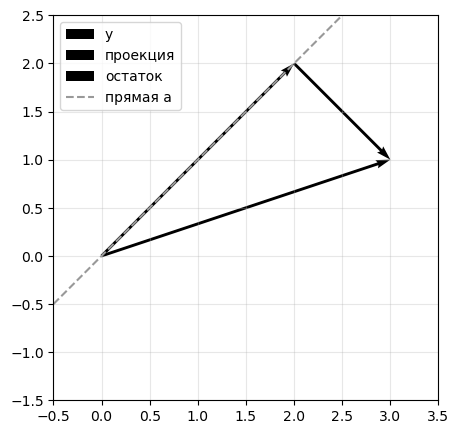

In [18]:
y_vector = np.array([3.0, 1.0])
a = np.array([1.0, 1.0])

coefficient = (a @ y_vector) / (a @ a)
y_projection = coefficient * a
residual = y_vector - y_projection

print("коэффициент c =", coefficient)
print("проекция =", y_projection)
print("остаток =", residual)
print("a @ остаток =", a @ residual)
print("норма остатка =", np.linalg.norm(residual))

plt.figure(figsize=(5, 5))
origin = np.zeros(2)
plt.quiver(*origin, *y_vector, angles="xy", scale_units="xy", scale=1, label="y")
plt.quiver(*origin, *y_projection, angles="xy", scale_units="xy", scale=1, label="проекция")
plt.quiver(*y_projection, *residual, angles="xy", scale_units="xy", scale=1, label="остаток")
plt.plot([-0.5, 3.5], [-0.5, 3.5], "--", color="0.6", label="прямая a")
plt.xlim(-0.5, 3.5)
plt.ylim(-1.5, 2.5)
plt.grid(alpha=0.3)
plt.legend()
plt.gca().set_aspect("equal")
plt.show()

## 8. Метод наименьших квадратов: первая модель данных


### Короткая теория

Добавим к матрице признаков столбец единиц для свободного члена:

$$
\mathbf D=
\begin{pmatrix}
1&X_{11}&X_{12}\\
\vdots&\vdots&\vdots\\
1&X_{81}&X_{82}
\end{pmatrix},
\qquad
\boldsymbol\beta=
\begin{pmatrix}\beta_0\\\beta_1\\\beta_2\end{pmatrix}.
$$

Предсказания имеют вид $\widehat{\mathbf y}=\mathbf D\boldsymbol\beta$. Когда восемь уравнений для трёх коэффициентов нельзя выполнить точно одновременно, выбирают коэффициенты, минимизирующие сумму квадратов ошибок:

$$
\widehat{\boldsymbol\beta}
=\underset{\boldsymbol\beta}{\operatorname{argmin}}
\frac12\lVert\mathbf D\boldsymbol\beta-\mathbf y\rVert_2^2.
$$

Нормальные уравнения имеют вид

$$
\mathbf D^{\mathsf T}\mathbf D\widehat{\boldsymbol\beta}
=\mathbf D^{\mathsf T}\mathbf y.
$$

В вычислениях используем `numpy.linalg.lstsq`, поскольку явно формировать обратную матрицу не требуется и численно это обычно надёжнее. Теорию см. на [с. 38–39](../02-linear-algebra/linear-algebra.pdf#page=38).


### Задание 8.1. Матричная запись регрессии

- **[Бумага]** Выпишите первую и последнюю строки уравнения $\widehat{\mathbf y}=\mathbf D\boldsymbol\beta$ в скалярной форме.
- **[Markdown]** Объясните роли $\beta_0$, $\beta_1$ и $\beta_2$, указав единицы изменения итогового балла.
- **[Python]** Постройте $\mathbf D$, найдите коэффициенты командой `np.linalg.lstsq(D, y, rcond=None)` и вычислите $\widehat{\mathbf y}$.
- **[Интерпретация]** Объясните знак каждого коэффициента. Не трактуйте коэффициент как причинный эффект: это описание данного небольшого набора, а не эксперимент.


#### Ваше решение

**Матричная запись.** $\widehat{\mathbf y}=\mathbf D\boldsymbol\beta$, где $\mathbf D$ — матрица $8\times3$ со столбцом единиц. В скалярной форме первая и последняя строки:
$$\widehat y_1=\beta_0+1\beta_1+2\beta_2,\qquad \widehat y_8=\beta_0+7\beta_1+10\beta_2 .$$

**Роли коэффициентов.** $\beta_0$ — базовый уровень балла при нулевых часах и нулевых комплектах; $\beta_1$ — прибавка балла за один дополнительный час практики при фиксированном числе комплектов; $\beta_2$ — прибавка за один дополнительный комплект при фиксированных часах.

**Числа.** $\widehat{\boldsymbol\beta}=(38.9787,\ 4.8936,\ 2.1064)^{\mathsf T}$; предсказания $\widehat{\mathbf y}=(48.0851,\ 52.9787,\ 55.0851,\ 62.0851,\ 69.0851,\ 78.1915,\ 85.1915,\ 94.2979)^{\mathsf T}$.

**Интерпретация.** Оба коэффициента положительны: больше часов и больше комплектов — выше прогноз. Это описание восьми наблюдений, а не причинный эффект; на других данных коэффициенты могут измениться.

In [19]:
D = np.column_stack([np.ones(len(X)), X])

beta, *_ = np.linalg.lstsq(D, y, rcond=None)
y_hat = D @ beta

print("D.shape =", D.shape)
print("beta =", beta)
print("y_hat =", y_hat)
print("первая строка: beta0 + 1*beta1 + 2*beta2 =", beta[0] + beta[1] + 2 * beta[2])
print("последняя строка: beta0 + 7*beta1 + 10*beta2 =", beta[0] + 7 * beta[1] + 10 * beta[2])

D.shape = (8, 3)
beta = [38.9787  4.8936  2.1064]
y_hat = [48.0851 52.9787 55.0851 62.0851 69.0851 78.1915 85.1915 94.2979]
первая строка: beta0 + 1*beta1 + 2*beta2 = 48.08510638297869
последняя строка: beta0 + 7*beta1 + 10*beta2 = 94.2978723404255


### Задание 8.2. Невязка и качество приближения

- **[Бумага]** Для одного выбранного студента вычислите предсказание по найденной формуле и его остаток $e_i=y_i-\widehat y_i$.
- **[Markdown]** Запишите определения

  $$
  \operatorname{SSE}=\sum_i(y_i-\widehat y_i)^2,
  \qquad
  R^2=1-\frac{\sum_i(y_i-\widehat y_i)^2}{\sum_i(y_i-\overline y)^2}.
  $$

- **[Python]** Вычислите SSE, RMSE и $R^2$, постройте график «наблюдение — предсказание» и график остатков.
- **[Интерпретация]** Объясните, что значит высокое $R^2$ именно для этих восьми наблюдений и почему оно само по себе не гарантирует хорошее качество на новых данных.


#### Ваше решение

**Определения.**
$$\operatorname{SSE}=\sum_i(y_i-\widehat y_i)^2,\qquad \operatorname{RMSE}=\sqrt{\tfrac1n\operatorname{SSE}},\qquad R^2=1-\frac{\operatorname{SSE}}{\sum_i(y_i-\overline y)^2}.$$

**Ручная проверка одного наблюдения.** Для Ани $\widehat y_1=38.9787+1\cdot4.8936+2\cdot2.1064=48.0851$, остаток $e_1=48-48.0851=-0.0851$.

**Числа.** $\operatorname{SSE}=2.8085$, $\operatorname{RMSE}=0.5925$, $R^2=0.9985$.

**Интерпретация.** $R^2=0.9985$ означает, что модель объясняет $99.85\%$ разброса баллов именно в этих восьми наблюдениях. Высокое значение не гарантирует качества на новых данных: наблюдений мало, признаки сильно коррелированы, а модель подобрана по тем же точкам, на которых измеряется $R^2$; на новых студентах ошибка может оказаться заметно больше.

остатки: [-0.0851 -0.9787 -0.0851  0.9149  0.9149 -0.1915 -0.1915 -0.2979]
SSE = 2.808511
RMSE = 0.592506
R2 = 0.998536


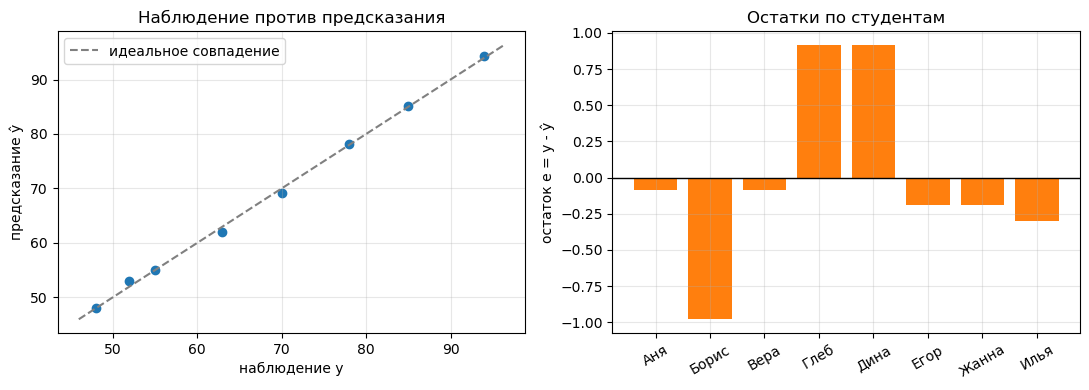

In [20]:
residuals = y - y_hat
SSE = float(np.sum(residuals ** 2))
RMSE = float(np.sqrt(np.mean(residuals ** 2)))
R2 = 1 - SSE / float(np.sum((y - y.mean()) ** 2))

print("остатки:", residuals)
print(f"SSE = {SSE:.6f}")
print(f"RMSE = {RMSE:.6f}")
print(f"R2 = {R2:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(y, y_hat, color="tab:blue")
limits = [min(y.min(), y_hat.min()) - 2, max(y.max(), y_hat.max()) + 2]
axes[0].plot(limits, limits, "--", color="0.5", label="идеальное совпадение")
axes[0].set_xlabel("наблюдение y")
axes[0].set_ylabel("предсказание ŷ")
axes[0].set_title("Наблюдение против предсказания")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].bar(student_names, residuals, color="tab:orange")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_ylabel("остаток e = y - ŷ")
axes[1].set_title("Остатки по студентам")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

### Задание 8.3. Регрессия как проекция

- **[Python]** Проверьте условия

  $$
  \mathbf D^{\mathsf T}(\mathbf y-\widehat{\mathbf y})\approx\mathbf0,
  \qquad
  \widehat{\mathbf y}\in\mathcal R(\mathbf D).
  $$

- **[Интерпретация]** Закончите фразу: «Вектор предсказаний является проекцией вектора результатов на пространство, потому что…»

> **Граница очной части.** К этому моменту пройдена единая линия от координат вектора до модели наименьших квадратов. Все незавершённые задания 1–8 нужно закончить дома. Разделы 9 и 10 — обязательное домашнее продолжение, а не отдельная лабораторная.


#### Ваше решение

**Проверка условий.**
$$\mathbf D^{\mathsf T}(\mathbf y-\widehat{\mathbf y})\approx(3.1\cdot10^{-13},\ 1.2\cdot10^{-12},\ 1.6\cdot10^{-12})^{\mathsf T}\approx\mathbf 0 .$$
Второе условие выполнено по построению: $\widehat{\mathbf y}=\mathbf D\widehat{\boldsymbol\beta}$ — линейная комбинация столбцов $\mathbf D$, значит лежит в $\mathcal R(\mathbf D)$.

**Интерпретация.** Вектор предсказаний является проекцией вектора результатов на пространство столбцов, потому что остаток $\mathbf y-\widehat{\mathbf y}$ ортогонален всем столбцам $\mathbf D$: именно это условие (нормальные уравнения) и характеризует ортогональную проекцию, а метод наименьших квадратов его обеспечивает.

In [21]:
orthogonality_check = D.T @ (y - y_hat)
print("D.T @ (y - y_hat) =", orthogonality_check)
print("максимальный модуль:", np.max(np.abs(orthogonality_check)))
print("норма остатка:", np.linalg.norm(y - y_hat))
print("y_hat в пространстве столбцов D:", np.linalg.matrix_rank(np.column_stack([D, y_hat])) == np.linalg.matrix_rank(D))

D.T @ (y - y_hat) = [0. 0. 0.]
максимальный модуль: 1.6271428648906294e-12
норма остатка: 1.6758611631927882
y_hat в пространстве столбцов D: True


## 9. Базовое PCA: новое направление вместо двух признаков


### Зачем это нужно

Часы практики и число выполненных комплектов в нашем наборе тесно связаны. PCA ищет ортонормированные направления, вдоль которых стандартизованные данные изменяются сильнее всего. Первое направление позволяет заменить два коррелирующих признака одной координатой, сохранив большую долю вариации.

Перед PCA признаки стандартизируются:

$$
Z_{ij}=\frac{X_{ij}-\mu_j}{s_j}.
$$

Затем строится ковариационная матрица

$$
\mathbf C=\frac{1}{n}\mathbf Z^{\mathsf T}\mathbf Z,
$$

а её собственные векторы задают главные направления:

$$
\mathbf C\mathbf u_k=\lambda_k\mathbf u_k.
$$

Доля объяснённой дисперсии компоненты равна

$$
r_k=\frac{\lambda_k}{\sum_j\lambda_j}.
$$

Собственные векторы и геометрию квадратичных форм см. на [с. 25–27](../02-linear-algebra/linear-algebra.pdf#page=25), стандартизацию и отбеливание — на [с. 27–28](../02-linear-algebra/linear-algebra.pdf#page=27).

![Геометрия собственных направлений](../02-linear-algebra/assets/figures/figure-06.png)

*Собственные векторы задают главные оси эллиптических линий уровня.*

![Стандартизация и отбеливание](../02-linear-algebra/assets/figures/figure-07.png)

*Переход от исходных признаков к стандартизованному и отбеленному представлению.*


### Задание 9.1. Выполнить готовый алгоритм

В ноутбуке уже дан код, который:

1. центрирует и стандартизирует $\mathbf X$;
2. строит $\mathbf C$;
3. получает собственные значения и векторы командой `np.linalg.eigh`;
4. сортирует компоненты по убыванию $\lambda_k$;
5. проектирует данные на первую компоненту;
6. восстанавливает приближение исходных признаков;
7. визуализирует исходные и восстановленные точки.

- **[Python]** Выполните готовые ячейки сверху вниз. Самостоятельная реализация PCA не требуется.
- **[Markdown]** Выпишите размерности $\mathbf X$, $\mathbf Z$, $\mathbf C$, матрицы собственных векторов и одномерных координат.
- **[Интерпретация]** Ответьте:
  1. какую долю вариации объясняет первая компонента;
  2. почему коэффициенты двух признаков в ней близки по модулю;
  3. какие студенты имеют крайние значения новой координаты;
  4. что потеряно при восстановлении по одной компоненте;
  5. почему одновременная смена знака собственного вектора и всех координат не меняет решения.


#### Ваше решение

**Размерности.** $\mathbf X$: $8\times2$; $\mathbf Z$: $8\times2$; $\mathbf C$: $2\times2$; матрица собственных векторов: $2\times2$; координаты $\mathbf s_1=\mathbf Z\mathbf u_1$: $8\times1$.

**Результаты.** $\mathbf C=\begin{pmatrix}1&0.98767\\0.98767&1\end{pmatrix}$, собственные значения $1.98767$ и $0.01233$, доли объяснённой дисперсии $99.38\%$ и $0.62\%$, первая компонента $\mathbf u_1\approx(0.7071,\ 0.7071)^{\mathsf T}$.

**Ответы.** 1) Первая компонента объясняет $99.38\%$ вариации. 2) Коэффициенты близки по модулю потому, что признаки почти коллинеарны (корреляция $0.9877$): направление наибольшей вариации идёт под $45^\circ$ к осям, и оба признака входят в него с равным весом. 3) Крайние значения координаты — у Ильи ($+2.41$) и Ани ($-1.78$). 4) При восстановлении по одной компоненте теряется направление с $0.62\%$ дисперсии — небольшая часть, поэтому точки восстанавливаются почти точно, но отклонения от главной прямой исчезают. 5) Смена знака $\mathbf u_1$ меняет знаки всех координат, произведение $\mathbf s_1\mathbf u_1^{\mathsf T}$ при этом не меняется, поэтому решение то же.

**Интерпретация.** PCA нашёл новую ось, вдоль которой студенты различаются сильнее всего; два исходных признака заменились одной координатой почти без потери информации.

Размерности: (8, 2) (8, 2) (2, 2) (2, 2) (8, 1)
Ковариационная матрица:
 [[1.     0.9877]
 [0.9877 1.    ]]
Собственные значения: [1.9877 0.0123]
Доли объяснённой дисперсии: [0.9938 0.0062]
Первая компонента: [0.7071 0.7071]


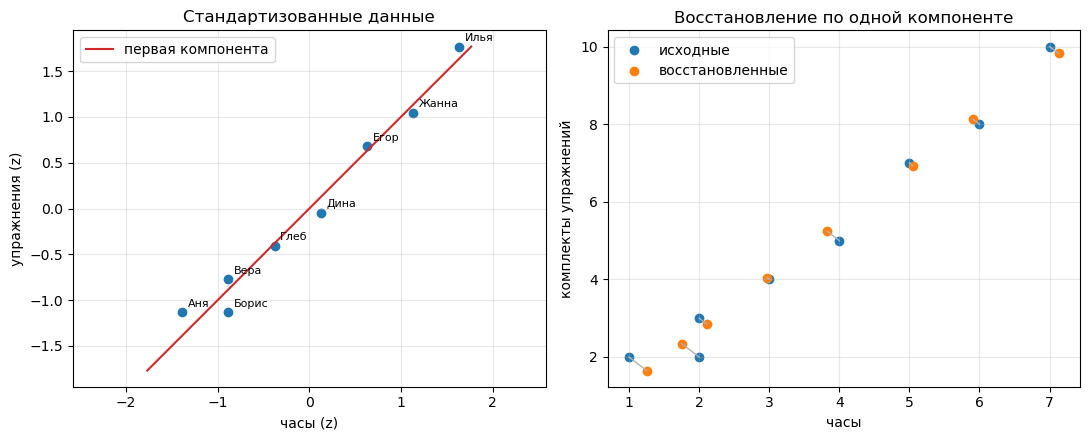

In [22]:
# Готовая реализация PCA: выполните её без изменений, затем интерпретируйте вывод.
mean_X = X.mean(axis=0)
scale_X = X.std(axis=0, ddof=0)
Z = (X - mean_X) / scale_X

C = Z.T @ Z / len(Z)
eigenvalues, eigenvectors = np.linalg.eigh(C)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
explained_ratio = eigenvalues / eigenvalues.sum()

scores_1d = Z @ eigenvectors[:, :1]
Z_reconstructed = scores_1d @ eigenvectors[:, :1].T
X_reconstructed = Z_reconstructed * scale_X + mean_X

print("Размерности:", X.shape, Z.shape, C.shape, eigenvectors.shape, scores_1d.shape)
print("Ковариационная матрица:\n", C)
print("Собственные значения:", eigenvalues)
print("Доли объяснённой дисперсии:", explained_ratio)
print("Первая компонента:", eigenvectors[:, 0])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(Z[:, 0], Z[:, 1], color="tab:blue")
for name, point in zip(student_names, Z):
    axes[0].annotate(name, point, xytext=(4, 4), textcoords="offset points", fontsize=8)
axis = np.linspace(-2.5, 2.5, 2)[:, None] * eigenvectors[:, 0]
axes[0].plot(axis[:, 0], axis[:, 1], color="tab:red", label="первая компонента")
axes[0].set_title("Стандартизованные данные")
axes[0].set_xlabel("часы (z)"); axes[0].set_ylabel("упражнения (z)")
axes[0].axis("equal"); axes[0].grid(alpha=0.3); axes[0].legend()

axes[1].scatter(X[:, 0], X[:, 1], label="исходные", color="tab:blue")
axes[1].scatter(X_reconstructed[:, 0], X_reconstructed[:, 1], label="восстановленные", color="tab:orange")
for original, restored in zip(X, X_reconstructed):
    axes[1].plot([original[0], restored[0]], [original[1], restored[1]], color="0.7", lw=1)
axes[1].set_title("Восстановление по одной компоненте")
axes[1].set_xlabel("часы"); axes[1].set_ylabel("комплекты упражнений")
axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout(); plt.show()


### Задание 9.2. Польза и ограничения

- **[Интерпретация]** Сформулируйте одним абзацем, когда сжатие двух признаков до одного полезно для визуализации или модели.
- **[Интерпретация]** Укажите не менее двух ограничений: PCA чувствителен к масштабу, описывает линейные направления и не использует целевой вектор $\mathbf y$ при выборе компонент.


#### Ваш ответ

Сжатие двух признаков до одной компоненты полезно, когда признаки сильно коррелированы и нужно упростить данные: для визуализации (точки рисуются на одной оси вместо двух), для борьбы с мультиколлинеарностью и как первый шаг отбора направлений вариации. В нашем наборе одна компонента объясняет $99.38\%$ дисперсии, поэтому потеря мала, а представление упрощается.

Ограничения: PCA чувствителен к масштабу — без стандартизации признак с большим разбросом (например, баллы) забирает почти всю дисперсию; он ищет только линейные направления, поэтому нелинейные структуры (скопления, «подковы») не описываются; он не использует целевой вектор $\mathbf y$, то есть выбирает направления максимальной вариации, а не максимальной связи с результатом. Наконец, главные компоненты сложно интерпретировать: они являются смесями исходных признаков.

In [23]:
# Небольшая численная опора для ответа об ограничениях.
correlation = np.corrcoef(X.T)[0, 1]
reconstruction_rmse = np.sqrt(np.mean((X - X_reconstructed) ** 2))
print("Корреляция исходных признаков:", correlation)
print("RMSE восстановления по одной компоненте:", reconstruction_rmse)


Корреляция исходных признаков: 0.9876688294984395
RMSE восстановления по одной компоненте: 0.18867066835176532


## 10. Базовое SVD: малоранговое приближение изображения


### Зачем это нужно

Для любой матрицы $\mathbf A\in\mathbb R^{m\times n}$ сингулярное разложение имеет вид

$$
\mathbf A=\mathbf U\mathbf S\mathbf V^{\mathsf T}.
$$

Если оставить только первые $k$ сингулярных чисел и соответствующие столбцы, получится приближение ранга $k$:

$$
\mathbf A_k
=\mathbf U_{:,1:k}\mathbf S_{1:k,1:k}\mathbf V_{:,1:k}^{\mathsf T}.
$$

Оно хранит $k(m+n+1)$ чисел вместо $mn$. Чем больше $k$, тем точнее восстановление, но тем меньше выигрыш в объёме. Основы SVD см. на [с. 30–31](../02-linear-algebra/linear-algebra.pdf#page=30), усечённое SVD и оценку хранения — на [с. 33–34](../02-linear-algebra/linear-algebra.pdf#page=33).

![Малоранговые приближения изображения](../02-linear-algebra/assets/figures/figure-09.png)

*Оригинал и приближения рангов 2, 5 и 20 из теоретического пособия.*


### Задание 10.1. Выполнить готовое SVD

Ноутбук загружает верхнее левое изображение из рис. 9, переводит его в оттенки серого и выполняет `np.linalg.svd`. Для $k\in\{2,5,20,50\}$ готовый код строит восстановление и считает относительную ошибку Фробениуса

$$
\varepsilon_k=
\frac{\lVert\mathbf A-\mathbf A_k\rVert_F}{\lVert\mathbf A\rVert_F}.
$$

- **[Python]** Выполните готовый код и получите четыре изображения, ошибки и оценки хранения.
- **[Markdown]** Составьте таблицу со столбцами: ранг $k$, относительная ошибка, количество хранимых чисел, доля от исходного объёма.
- **[Интерпретация]** Опишите, какие структуры появляются уже при $k=2$, какие детали добавляются при $k=5$ и $k=20$, и насколько заметно улучшение при $k=50$.
- **[Интерпретация]** Проверьте, что ошибка не возрастает с ростом $k$. Объясните, почему это ожидаемо.


#### Ваше решение

**Результаты.** Матрица изображения после прореживания: $126\times263$, то есть $33138$ значений.

| Ранг $k$ | Относительная ошибка | Хранимых чисел | Доля от исходного объёма |
|---:|---:|---:|---:|
| 2 | 0.1056 | 780 | 2.35% |
| 5 | 0.0440 | 1950 | 5.88% |
| 20 | 0.0369 | 7800 | 23.54% |
| 50 | 0.0255 | 19500 | 58.84% |

**Интерпретация.** Уже при $k=2$ видны крупные структуры: общий градиент яркости и основное пятно, но мелкие детали размыты. При $k=5$ добавляются очертания кольца и границы пятна; $k=20$ передаёт мелкую текстуру, а $k=50$ улучшает её незначительно ($0.0369\to0.0255$), но требует более половины исходного объёма. Ошибка не возрастает при увеличении $k$, потому что $k$-е сингулярное число не превосходит первые: отбрасываемая часть в разложении $\mathbf A=\sum\sigma_i\mathbf u_i\mathbf v_i^{\mathsf T}$ становится меньше, и по теореме Эккарта–Янга $\mathbf A_k$ — оптимальное приближение ранга $k$ в норме Фробениуса.

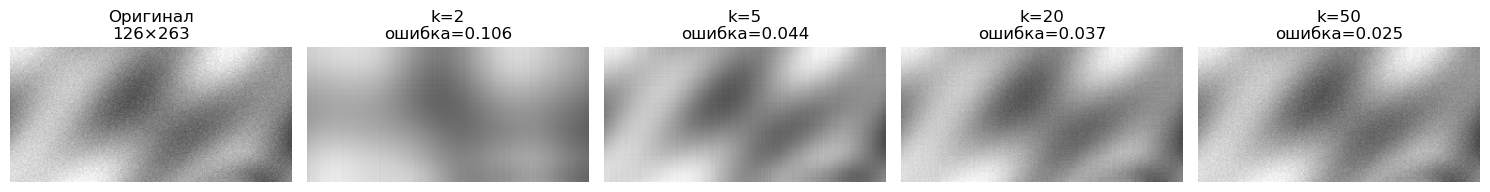

Исходное число значений: 33138
 k | отн. ошибка | хранить чисел | доля исходного
 2 |      0.10556 |           780 |        2.354%
 5 |      0.04404 |          1950 |        5.884%
20 |      0.03694 |          7800 |       23.538%
50 |      0.02547 |         19500 |       58.845%
Ошибка невозрастает: True


In [24]:
# Готовая демонстрация SVD на изображении из теоретического пособия.
figure = plt.imread("../02-linear-algebra/assets/figures/figure-09.png")
gray = 0.2126 * figure[..., 0] + 0.7152 * figure[..., 1] + 0.0722 * figure[..., 2]

# Верхний левый фрагмент рис. 9; прореживание лишь уменьшает время вычисления.
image_matrix = gray[0:252:2, 55:581:2]
U, singular_values, Vt = np.linalg.svd(image_matrix, full_matrices=False)

ranks = [2, 5, 20, 50]
relative_errors = []
storage_numbers = []
m, n = image_matrix.shape

fig, axes = plt.subplots(1, 5, figsize=(15, 3.3))
axes[0].imshow(image_matrix, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Оригинал\n{m}×{n}")
axes[0].axis("off")

for ax, k in zip(axes[1:], ranks):
    approximation = (U[:, :k] * singular_values[:k]) @ Vt[:k, :]
    error = np.linalg.norm(image_matrix - approximation, ord="fro") / np.linalg.norm(image_matrix, ord="fro")
    storage = k * (m + n + 1)
    relative_errors.append(error)
    storage_numbers.append(storage)
    ax.imshow(approximation, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"k={k}\nошибка={error:.3f}")
    ax.axis("off")

plt.tight_layout(); plt.show()

print("Исходное число значений:", m * n)
print(" k | отн. ошибка | хранить чисел | доля исходного")
for k, error, storage in zip(ranks, relative_errors, storage_numbers):
    print(f"{k:2d} | {error:12.5f} | {storage:13d} | {storage / (m*n):13.3%}")
print("Ошибка невозрастает:", np.all(np.diff(relative_errors) <= 1e-12))


### Задание 10.2. Связь PCA и SVD

В ноутбуке дополнительно выполняется SVD стандартизованной матрицы учебной активности $\mathbf Z$. Правые сингулярные векторы задают те же направления признаков, что и собственные векторы $\mathbf Z^{\mathsf T}\mathbf Z$.

- **[Python]** Сравните первый собственный вектор PCA с первой строкой $\mathbf V^{\mathsf T}$ с точностью до знака.
- **[Интерпретация]** Объясните результат без вывода формул: PCA описывает направления вариации данных, а SVD предоставляет удобный общий способ получить эти направления непосредственно из матрицы.


#### Ваше решение

**Сравнение.** Вектор PCA $\mathbf u_1\approx(0.7071,\ 0.7071)^{\mathsf T}$, первая строка $\mathbf V^{\mathsf T}$ совпадает с ним с точностью до знака: модуль скалярного произведения равен $1.0$ (в выводе `agreement_up_to_sign`). Сингулярные числа $\mathbf Z$ связаны с собственными значениями: $\sigma_1^2/n\approx\lambda_1$.

**Интерпретация.** PCA описывает направления вариации данных и ищет их через собственные векторы ковариационной матрицы $\mathbf Z^{\mathsf T}\mathbf Z/n$. SVD даёт те же направления напрямую из матрицы: правые сингулярные векторы $\mathbf V$ — это собственные векторы $\mathbf Z^{\mathsf T}\mathbf Z$, поэтому первые направления совпадают. Различие лишь в способе вычисления и в том, что SVD не требует явного построения ковариационной матрицы; знак вектора при этом произволен и на решение не влияет.

In [25]:
# SVD той же стандартизованной матрицы Z, которая использовалась в PCA.
U_data, s_data, Vt_data = np.linalg.svd(Z, full_matrices=False)
pca_direction = eigenvectors[:, 0]
svd_direction = Vt_data[0]
agreement_up_to_sign = abs(pca_direction @ svd_direction)

print("Направление PCA:", pca_direction)
print("Направление SVD:", svd_direction)
print("|скалярное произведение|:", agreement_up_to_sign)
print("Сингулярные числа:", s_data)


Направление PCA: [0.7071 0.7071]
Направление SVD: [0.7071 0.7071]
|скалярное произведение|: 1.0
Сингулярные числа: [3.9876 0.3141]


## 11. Итоговая интерпретация


### Задание 11.1. Карта понятий

- **[Markdown]** Напишите связный текст из 8–12 предложений, использовав термины: *вектор наблюдения*, *матрица данных*, *линейное отображение*, *ранг*, *система уравнений*, *проекция*, *наименьшие квадраты*, *главная компонента*, *сингулярное число*, *малоранговое приближение*.
- **[Интерпретация]** Для каждого из трёх итоговых результатов — регрессия, PCA, SVD — укажите:
  1. какой объект подаётся на вход;
  2. какой объект получается на выходе;
  3. какую практическую пользу даёт результат;
  4. какая информация при этом может быть потеряна или неправильно истолкована.


#### Ваш ответ

Вектор наблюдения описывает один объект — например, студента парой чисел (часы практики, комплекты упражнений); матрица данных собирает такие векторы по строкам, и её размерность $8\times2$ означает восемь объектов и два признака. Линейное отображение переводит признаки в новое представление умножением на матрицу, а его свойства определяются столбцами — образами базисных векторов. Ранг показывает, сколько независимых направлений сохранилось: если он меньше числа столбцов, часть информации потеряна, и именно поэтому вырожденные матрицы необратимы, а определитель у них равен нулю.

Система уравнений $\mathbf A\mathbf x=\mathbf b$ восстанавливает неизвестные параметры; для квадратной невырожденной системы решение единственно, для недоопределённой остаётся свободный параметр, а для переопределённой точного решения может не быть. Тогда на помощь приходит проекция: ближайшая точка пространства столбцов, а метод наименьших квадратов даёт коэффициенты $\widehat{\boldsymbol\beta}=(\mathbf D^{\mathsf T}\mathbf D)^{-1}\mathbf D^{\mathsf T}\mathbf y$, при которых остаток ортогонален столбцам $\mathbf D$. В нашем наборе регрессия объясняет $R^2=0.9985$, то есть почти весь разброс баллов.

Главная компонента обобщает эту идею: вместо целевого вектора $\mathbf y$ ищется направление максимальной вариации данных, и два коррелирующих признака заменяются одной координатой ($99.38\%$ дисперсии). Сингулярное число показывает масштаб изменения вдоль соответствующего направления, а малоранговое приближение оставляет только несколько таких направлений, экономя объём хранения ($k=5$ даёт ошибку $0.044$ при $5.9\%$ исходного объёма).

| Результат | Вход | Выход | Польза | Что теряется или истолковывается неверно |
|---|---|---|---|---|
| Регрессия | $\mathbf D$ ($8\times3$) и $\mathbf y$ ($8$) | $\widehat{\boldsymbol\beta}$ ($3$) и $\widehat{\mathbf y}$ | прогноз балла и вклад каждого признака | причинный смысл коэффициентов; качество на новых данных |
| PCA | матрица $\mathbf X$ ($8\times2$) | собственные значения и векторы, координаты $\mathbf s_1$ ($8\times1$) | сжатие коррелирующих признаков, визуализация | часть дисперсии ($0.62\%$) и интерпретируемость осей |
| SVD | изображение как матрица $126\times263$ | $\mathbf U$, $\sigma$, $\mathbf V^{\mathsf T}$ и $\mathbf A_k$ | малоранговое приближение и оценка объёма хранения | мелкие детали; «главное» направление не обязательно самое важное по смыслу |

## Что сдавать

Сдаётся заполненный студенческий ноутбук. Перед отправкой выполните все ячейки сверху вниз и убедитесь, что выводы сохранены.

Чек-лист:

- все задания **[Бумага]** перенесены в Markdown с промежуточными действиями;
- все ячейки **[Python]** выполняются без ошибок;
- размерности матриц указаны и согласованы;
- ответы **[Интерпретация]** относятся к конкретным полученным числам и графикам;
- невязка квадратной системы близка к нулю;
- для регрессии вычислены коэффициенты, остатки, SSE, RMSE и $R^2$;
- для PCA указана объяснённая дисперсия и разобрано восстановление;
- для SVD заполнена таблица рангов 2, 5, 20 и 50, а ошибка не возрастает;
- в последнем разделе дана единая связь между всеми этапами работы.


## Справка по синтаксису

В Markdown-ячейке формула внутри строки записывается как `$\mathbf y=\mathbf A\mathbf x$`, а отдельная формула — между двойными знаками доллара. В NumPy:

```python
A.shape                  # размерность массива
A.T                      # транспонирование
A @ B                    # матричное произведение
np.dot(a, b)             # скалярное произведение
np.linalg.norm(a)        # евклидова норма
np.linalg.det(A)         # определитель
np.linalg.matrix_rank(A) # ранг
np.linalg.solve(A, b)    # решение квадратной системы
np.linalg.lstsq(A, b, rcond=None)  # наименьшие квадраты
np.linalg.eigh(C)        # спектральное разложение симметричной матрицы
np.linalg.svd(A)         # сингулярное разложение
```

Все необходимые данные и изображения находятся в проекте; доступ к интернету не требуется.
